# Atividade 3: YOLO11 no dataset Thesis (resíduos recicláveis)

Dataset: <https://universe.roboflow.com/ed-mikael-bebic-iyvku/thesis-efjq4> (versão 31, 4 classes, CC BY 4.0).

Antes de rodar: ativar a GPU (T4) e criar ROBOFLOW_API_KEY nos "Secrets" do Colab com "Acesso ao notebook" ligado.

In [1]:
!pip install -q ultralytics roboflow

import ultralytics
ultralytics.checks()  # confirma versão e GPU disponível

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


In [2]:
# Baixa o dataset no formato YOLOv8 (a chave vem dos Secrets do Colab, não fica no código)
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace("ed-mikael-bebic-iyvku").project("thesis-efjq4")
dataset = project.version(31).download("yolov8", location="/content/dataset")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset in yolov8:: 100%|██████████| 4414/4414 [00:02<00:00, 1514.30it/s]


In [3]:
# Inspeciona o dataset: data.yaml e contagem de imagens e labels
import os, glob

root = "/content/dataset"
print(open(f"{root}/data.yaml").read())

for split in ["train", "valid", "test"]:
    imgs = glob.glob(f"{root}/{split}/images/*")
    lbls = glob.glob(f"{root}/{split}/labels/*")
    print(split, "-> imagens:", len(imgs), "| labels:", len(lbls))

names:
- can
- food-wrapper
- paper
- plastic bottle
nc: 4
roboflow:
  license: CC BY 4.0
  project: thesis-efjq4
  url: https://universe.roboflow.com/ed-mikael-bebic-iyvku/thesis-efjq4/dataset/31
  version: 31
  workspace: ed-mikael-bebic-iyvku
test: ../test/images
train: ../train/images
val: ../valid/images

train -> imagens: 1944 | labels: 1944
valid -> imagens: 183 | labels: 183
test -> imagens: 74 | labels: 74


In [4]:
# Corrige os caminhos do data.yaml para absolutos (evita erro de pasta não encontrada)
import yaml

cfg = yaml.safe_load(open(f"{root}/data.yaml"))
cfg["train"] = f"{root}/train/images"
cfg["val"] = f"{root}/valid/images"
cfg["test"] = f"{root}/test/images"
yaml.safe_dump(cfg, open(f"{root}/data.yaml", "w"))
print(open(f"{root}/data.yaml").read())

names:
- can
- food-wrapper
- paper
- plastic bottle
nc: 4
roboflow:
  license: CC BY 4.0
  project: thesis-efjq4
  url: https://universe.roboflow.com/ed-mikael-bebic-iyvku/thesis-efjq4/dataset/31
  version: 31
  workspace: ed-mikael-bebic-iyvku
test: /content/dataset/test/images
train: /content/dataset/train/images
val: /content/dataset/valid/images



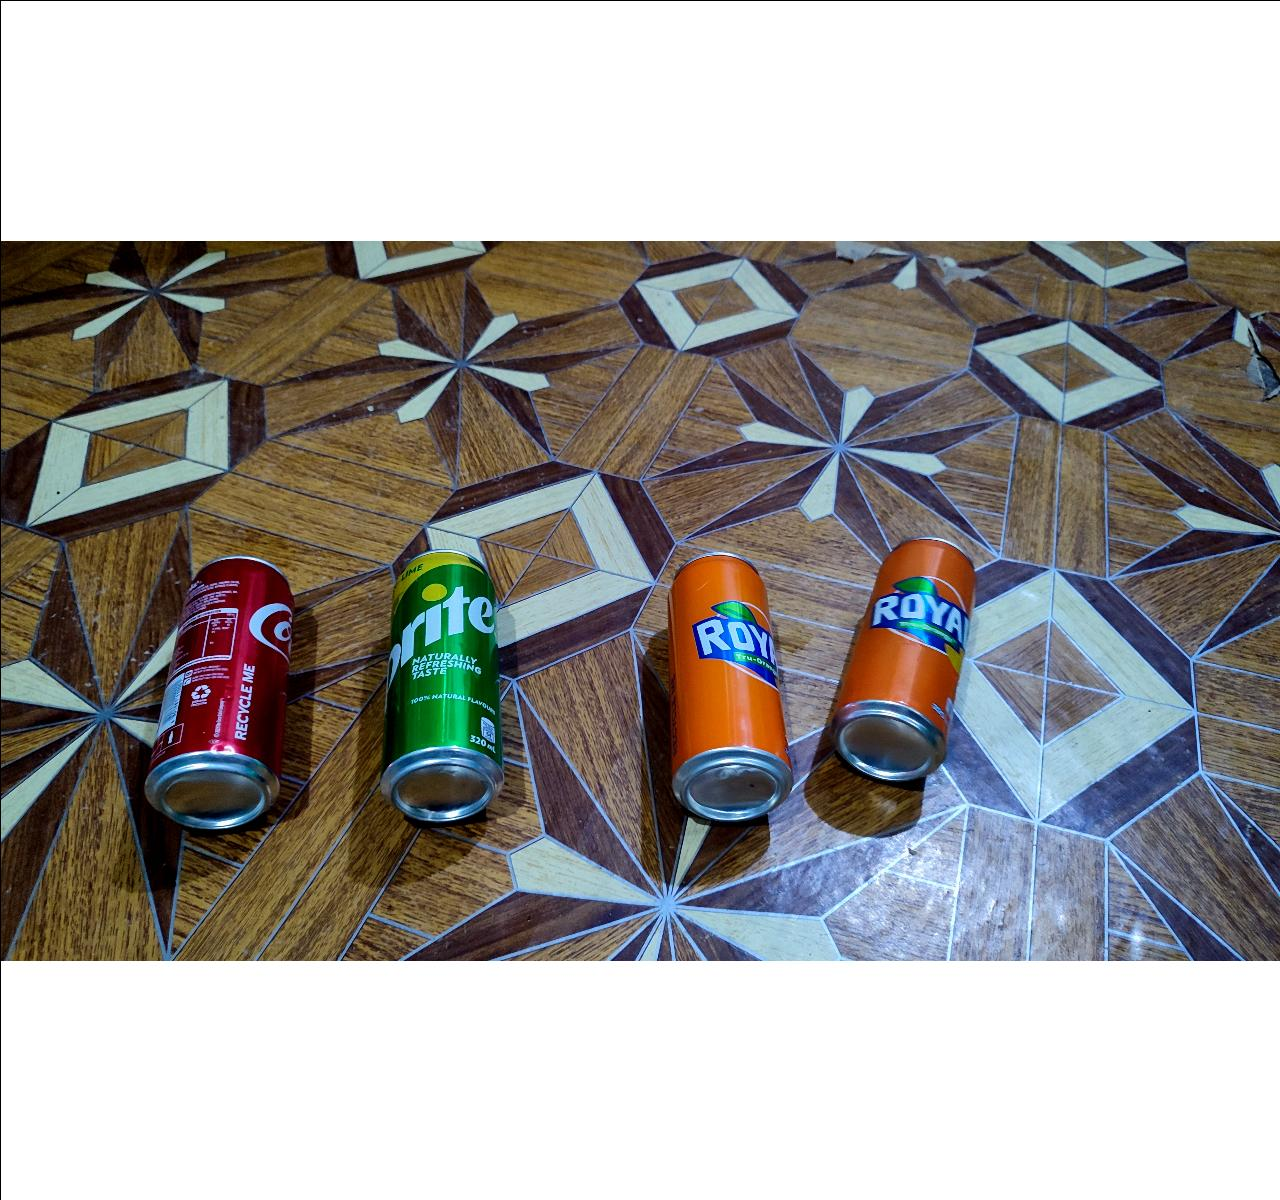

classe: 0 (can) | x_centro: 0.170 | y_centro: 0.578 | largura: 0.117 | altura: 0.227 (convertido de polígono)
classe: 0 (can) | x_centro: 0.345 | y_centro: 0.572 | largura: 0.096 | altura: 0.227 (convertido de polígono)
classe: 0 (can) | x_centro: 0.570 | y_centro: 0.573 | largura: 0.098 | altura: 0.225 (convertido de polígono)
classe: 0 (can) | x_centro: 0.705 | y_centro: 0.550 | largura: 0.113 | altura: 0.204 (convertido de polígono)


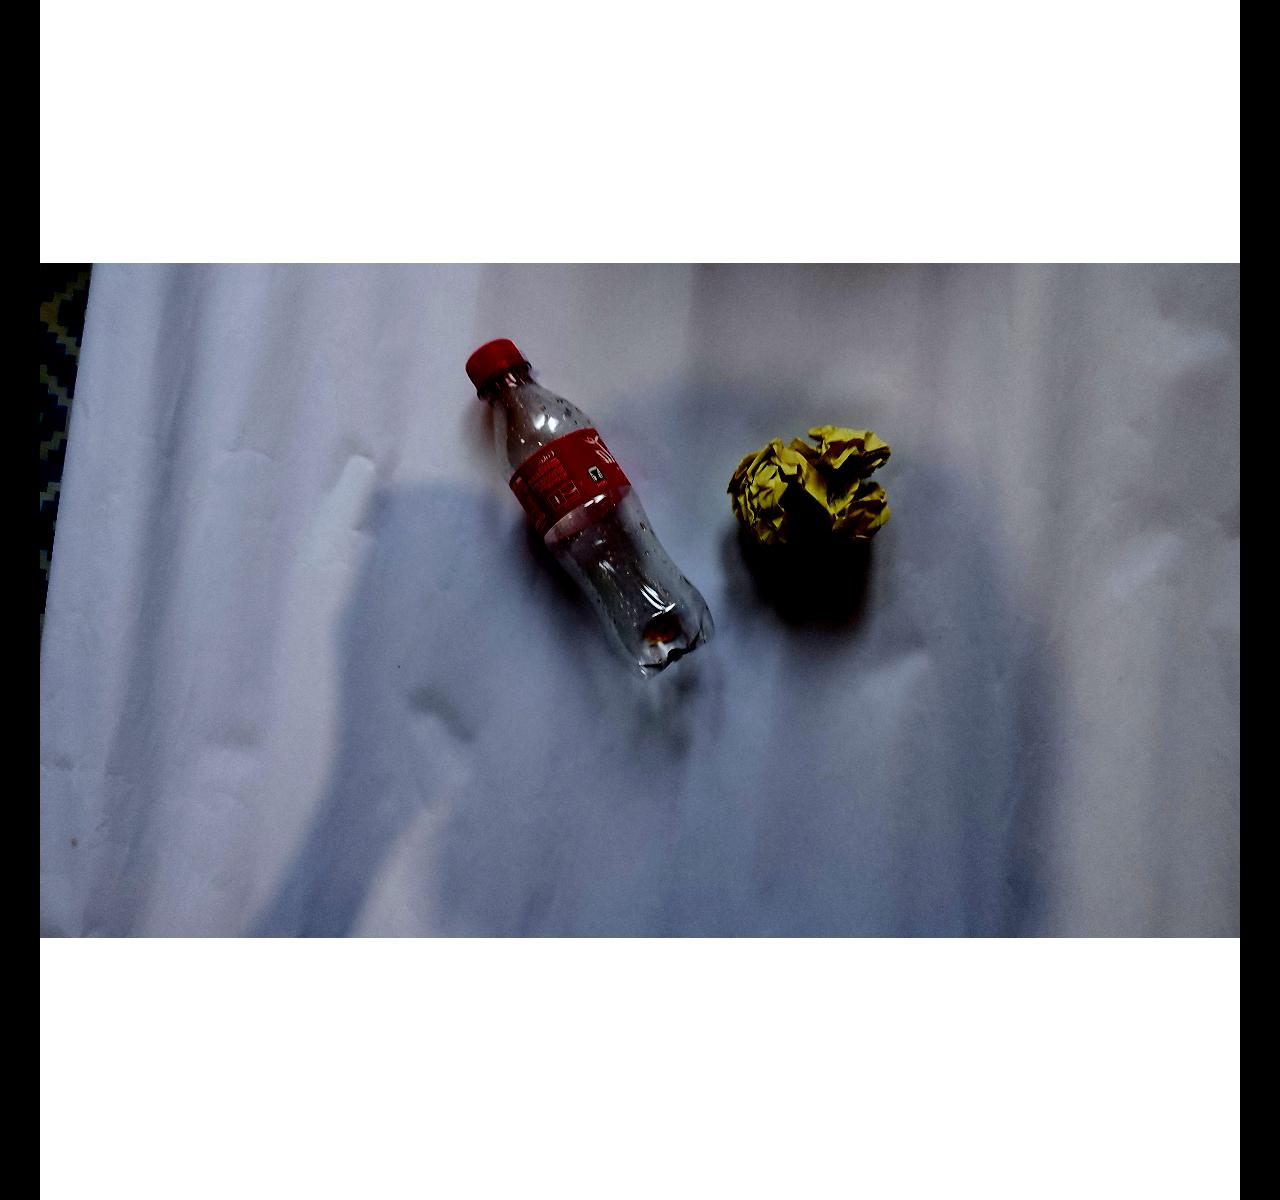

classe: 3 (plastic bottle) | x_centro: 0.461 | y_centro: 0.422 | largura: 0.192 | altura: 0.281 (convertido de polígono)
classe: 2 (paper) | x_centro: 0.633 | y_centro: 0.408 | largura: 0.126 | altura: 0.107 (convertido de polígono)


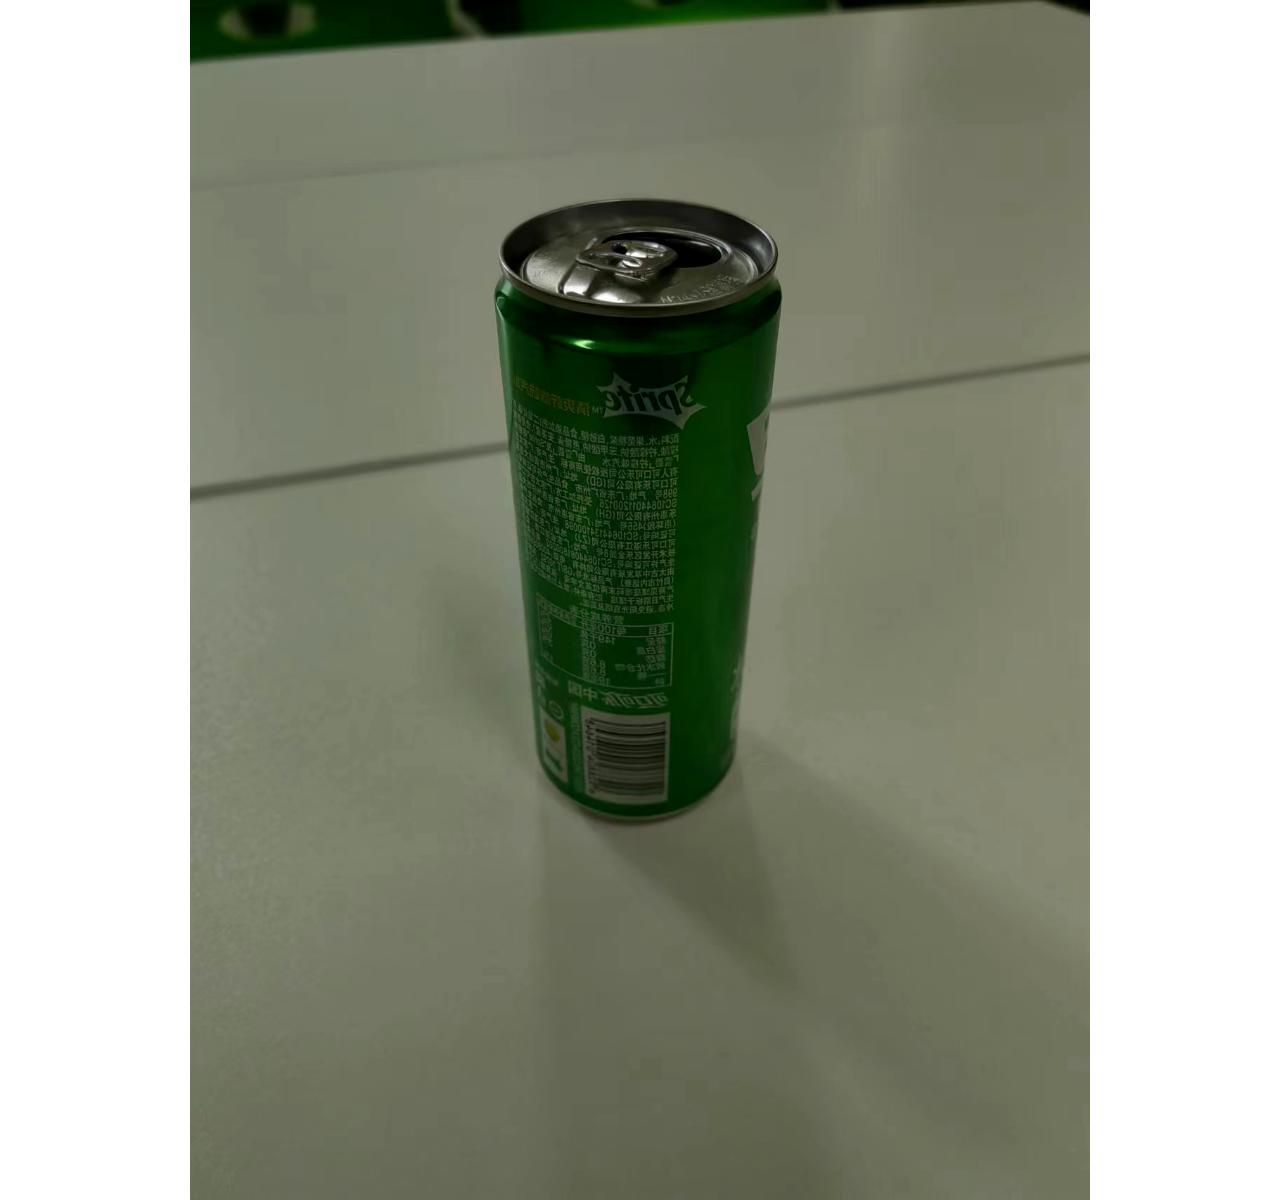

classe: 0 (can) | x_centro: 0.499 | y_centro: 0.428 | largura: 0.226 | altura: 0.521 (convertido de polígono)


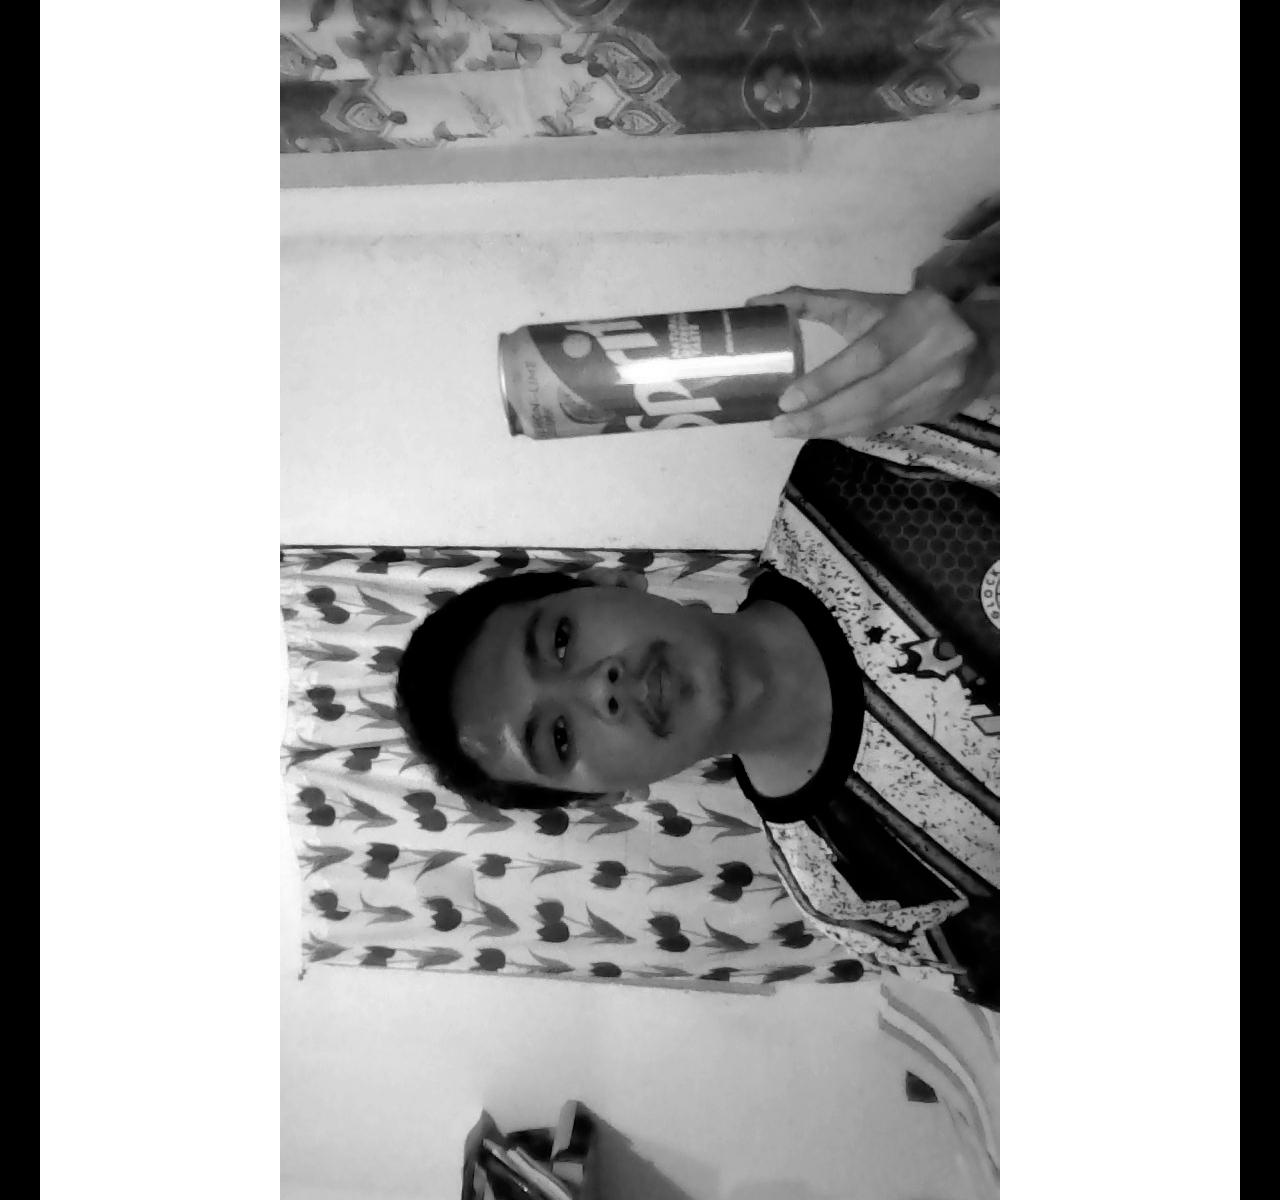

classe: 0 (can) | x_centro: 0.507 | y_centro: 0.309 | largura: 0.232 | altura: 0.110 (convertido de polígono)


In [5]:
# 4 imagens de treino, cada uma com o seu label: classe x_centro y_centro largura altura (0 a 1)
import random
from IPython.display import Image, display

amostras = random.sample(glob.glob(f"{root}/train/images/*"), 4)
for p in amostras:
    display(Image(p, width=300))
    label = p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    for linha in open(label).read().splitlines():
        c, *v = linha.split()
        v = [float(x) for x in v]
        obs = ""
        if len(v) > 4:  # anotação em polígono (x1 y1 x2 y2 ...): converte para a caixa que o envolve
            xs, ys = v[0::2], v[1::2]
            v = [(min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2, max(xs) - min(xs), max(ys) - min(ys)]
            obs = " (convertido de polígono)"
        xc, yc, w, h = v
        print(f"classe: {c} ({cfg['names'][int(c)]}) | x_centro: {xc:.3f} | y_centro: {yc:.3f} | "
              f"largura: {w:.3f} | altura: {h:.3f}{obs}")

In [6]:
# Treina a partir dos pesos pré-treinados (transfer learning)
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
results = model.train(
    data=f"{root}/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project="/content/runs",
    name="thesis",
)

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=thesis, nbs=64, nms=None, opset=None, optimize=False, optimizer

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3054.7±1106.8 MB/s, size: 119.9 KB)
val: Scanning /content/dataset/valid/labels.cache... 183 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 183/183 51.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 3.0it/s 4.1s
                   all        183        442      0.925      0.901       0.92      0.855
                   can         58        143      0.964      0.945      0.979      0.931
          food-wrapper         30         42      0.823      0.774      0.783      0.707
                 paper         57        187       0.97      0.957      0.981      0.923
        plastic bottle         48         70      0.942      0.929      0.936      0.858
Speed: 3.3ms preprocess, 5.6ms inference, 0

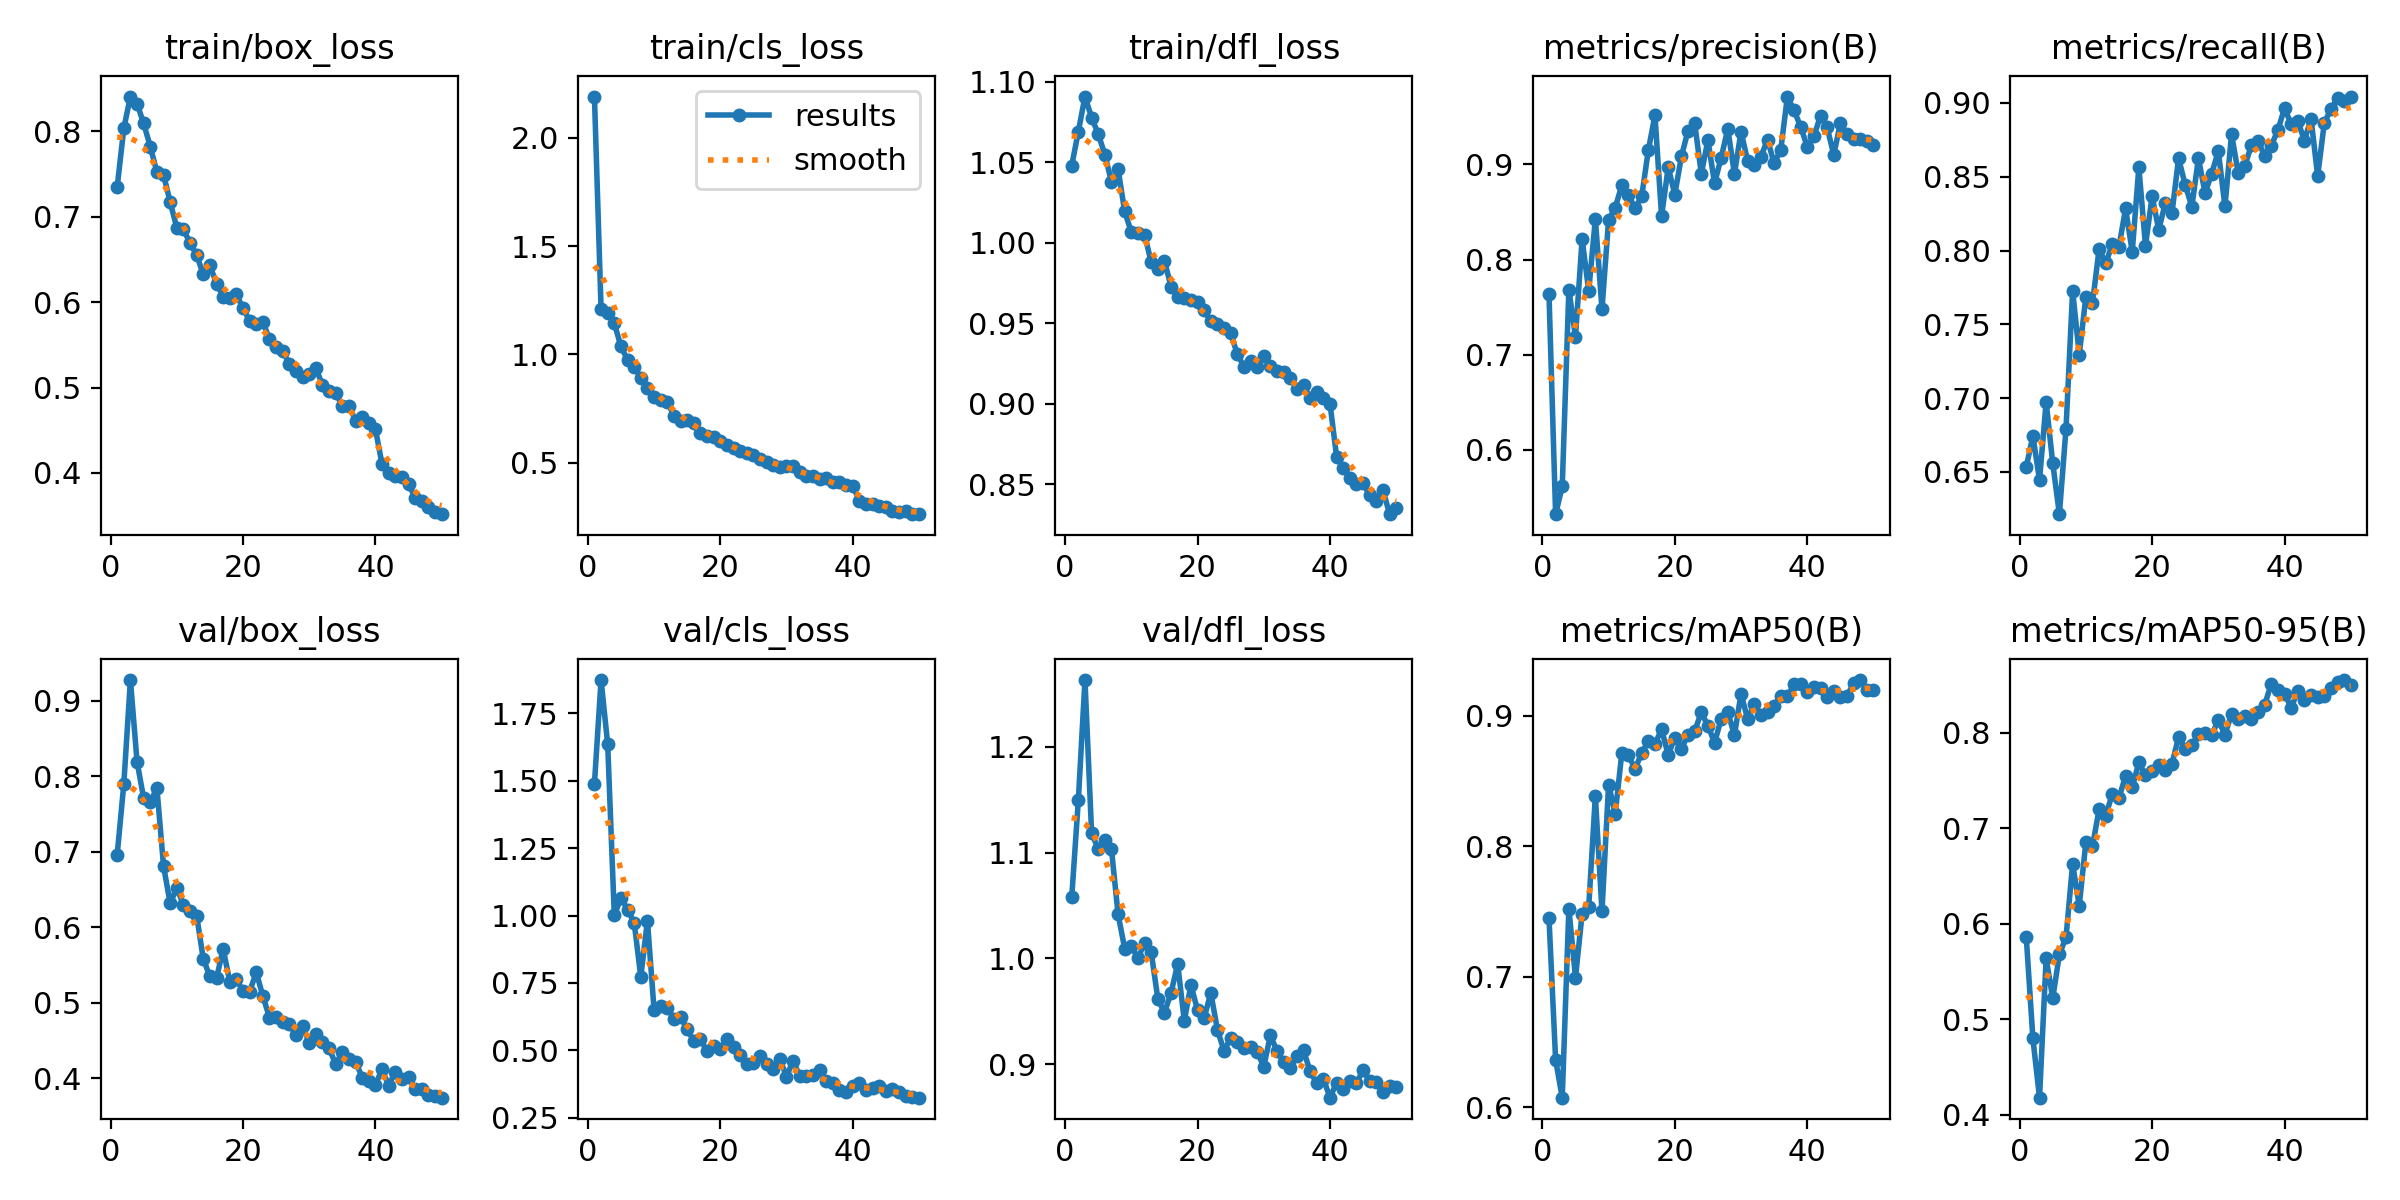

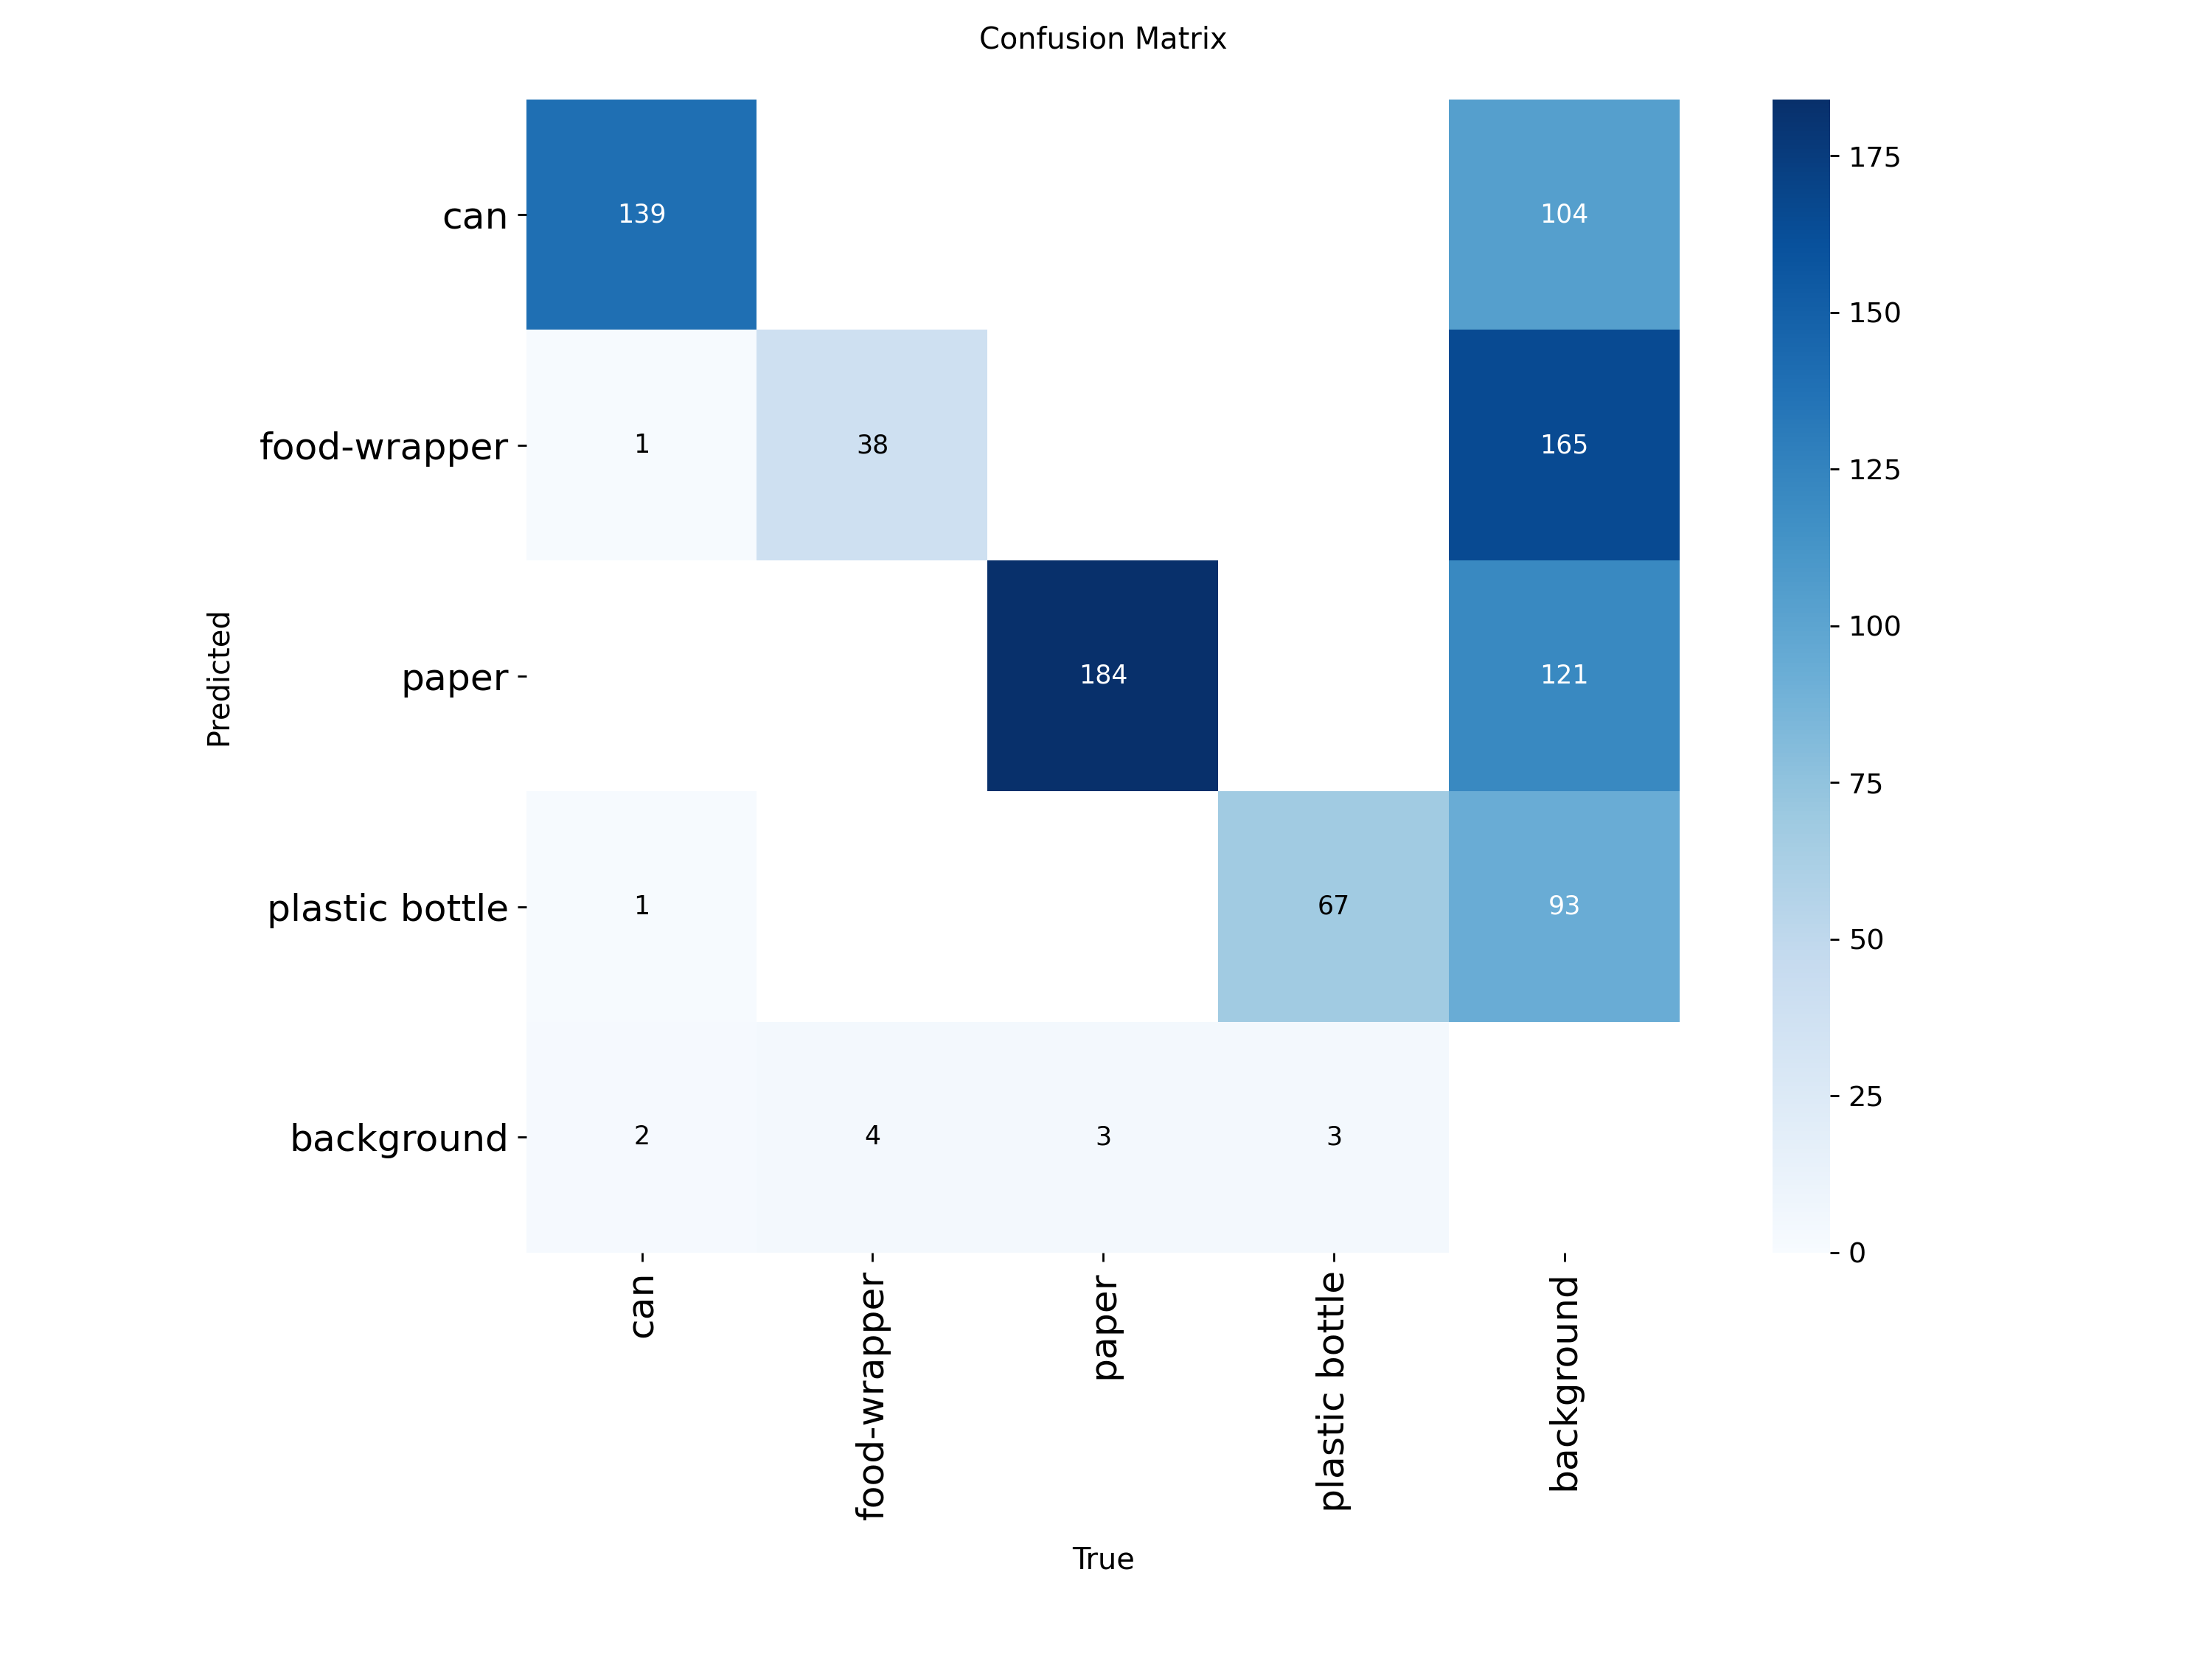

In [7]:
# Avalia no conjunto de validação e mostra os gráficos
metrics = model.val()
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

display(Image("/content/runs/thesis/results.png", width=900))
display(Image("/content/runs/thesis/confusion_matrix.png", width=600))

## Uso do modelo treinado

O treino gera o arquivo `best.pt`. O `uso.py` é um programa separado do treino: precisa só da biblioteca
`ultralytics` e do `best.pt`, sem dataset nem GPU, e por isso roda em qualquer computador.
Aqui ele é usado em 3 imagens do conjunto de teste, que o modelo não viu no treino.

Para testar com outras imagens, envie-as através dos "Arquivos" do Colab e rode `!python uso.py foto.jpg`.


0: 608x640 1 plastic bottle, 12.4ms
Speed: 46.0ms preprocess, 12.4ms inference, 26.2ms postprocess per image at shape (1, 3, 608, 640)
Results saved to /content/runs/detect/predict
/content/dataset/test/images/IMG_20231112_164704_jpg.rf.58392c16141d549bf763882d1ffe0cd9.jpg
classe: 3 (plastic bottle) | confiança: 0.940
  x_centro: 0.466 | y_centro: 0.403 | largura: 0.148 | altura: 0.401


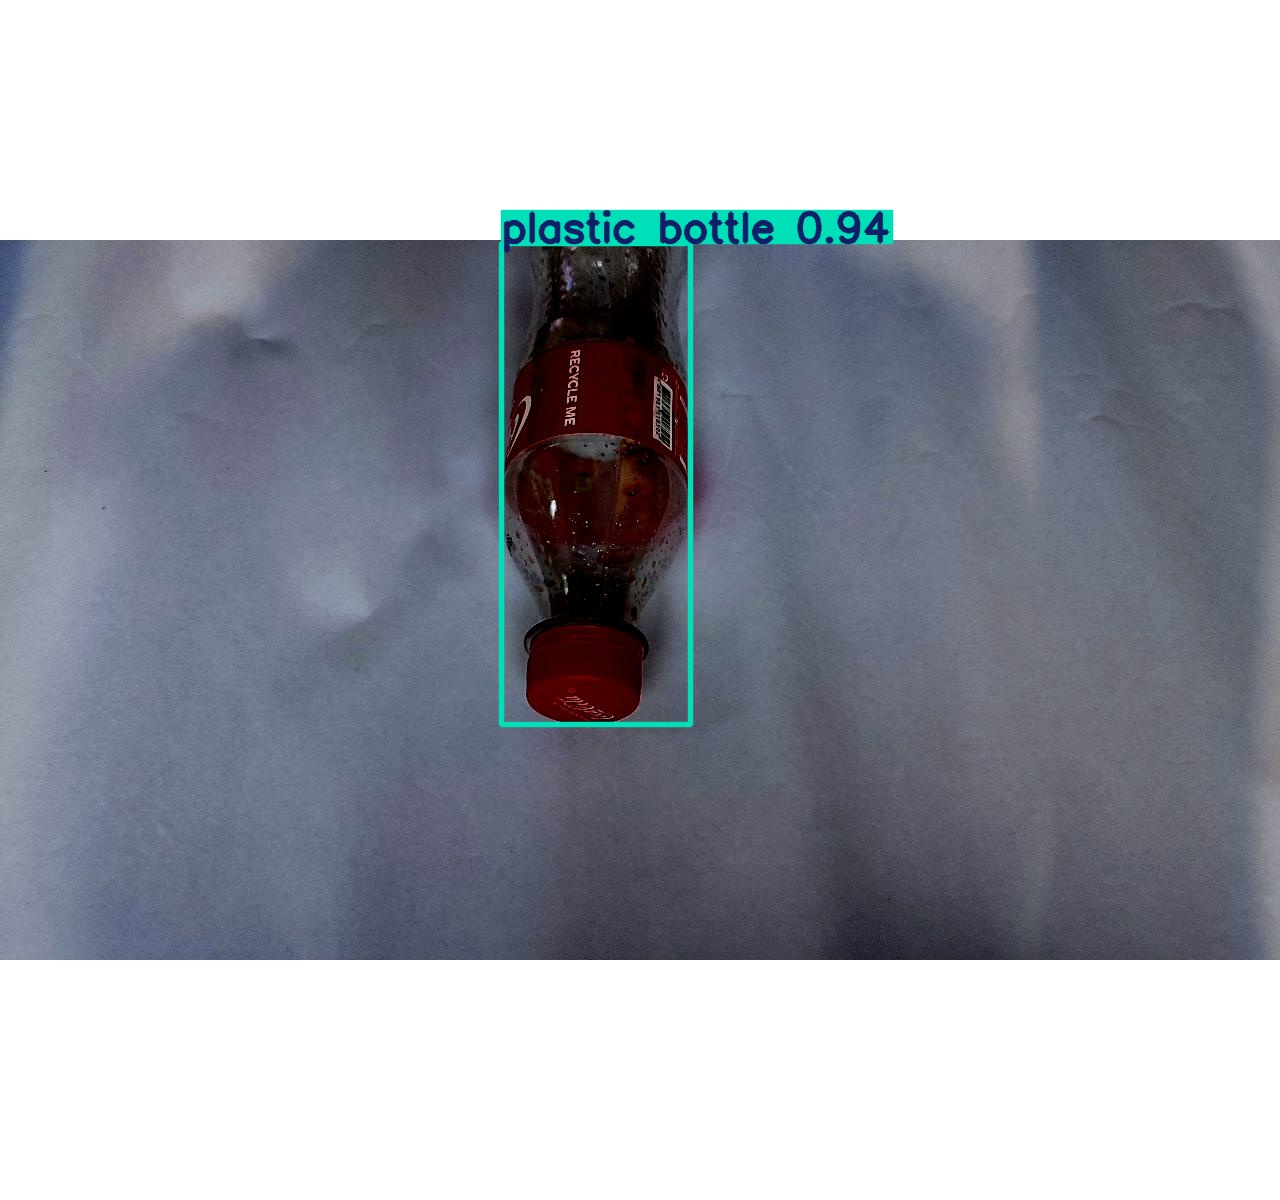


0: 608x640 6 cans, 9.1ms
Speed: 32.5ms preprocess, 9.1ms inference, 19.3ms postprocess per image at shape (1, 3, 608, 640)
Results saved to /content/runs/detect/predict
/content/dataset/test/images/-98_jpg.rf.c6555804f0cb42832be39193812fa6be.jpg
classe: 0 (can) | confiança: 0.952
  x_centro: 0.549 | y_centro: 0.745 | largura: 0.484 | altura: 0.444
classe: 0 (can) | confiança: 0.952
  x_centro: 0.485 | y_centro: 0.321 | largura: 0.276 | altura: 0.509
classe: 0 (can) | confiança: 0.948
  x_centro: 0.769 | y_centro: 0.289 | largura: 0.331 | altura: 0.517
classe: 0 (can) | confiança: 0.948
  x_centro: 0.237 | y_centro: 0.305 | largura: 0.282 | altura: 0.527
classe: 0 (can) | confiança: 0.911
  x_centro: 0.866 | y_centro: 0.838 | largura: 0.204 | altura: 0.221
classe: 0 (can) | confiança: 0.797
  x_centro: 0.901 | y_centro: 0.267 | largura: 0.083 | altura: 0.261


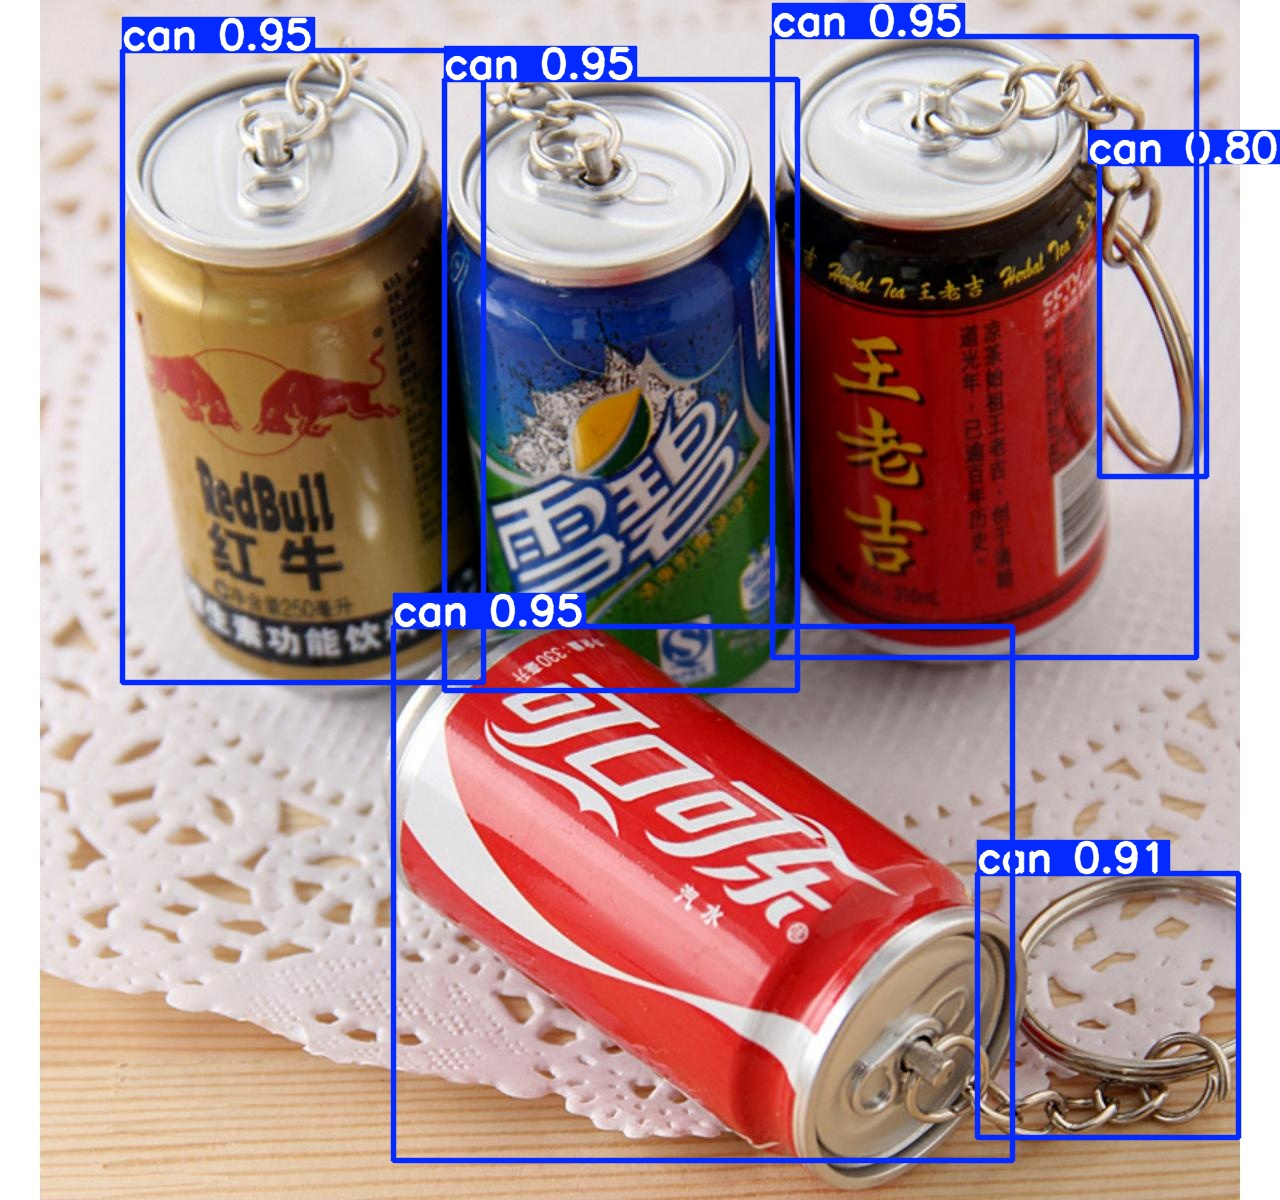


0: 608x640 1 paper, 11.0ms
Speed: 32.1ms preprocess, 11.0ms inference, 26.0ms postprocess per image at shape (1, 3, 608, 640)
Results saved to /content/runs/detect/predict
/content/dataset/test/images/images51_jpg.rf.06395dff71813666c5c0e985f45054e7.jpg
classe: 2 (paper) | confiança: 0.963
  x_centro: 0.471 | y_centro: 0.518 | largura: 0.480 | altura: 0.508


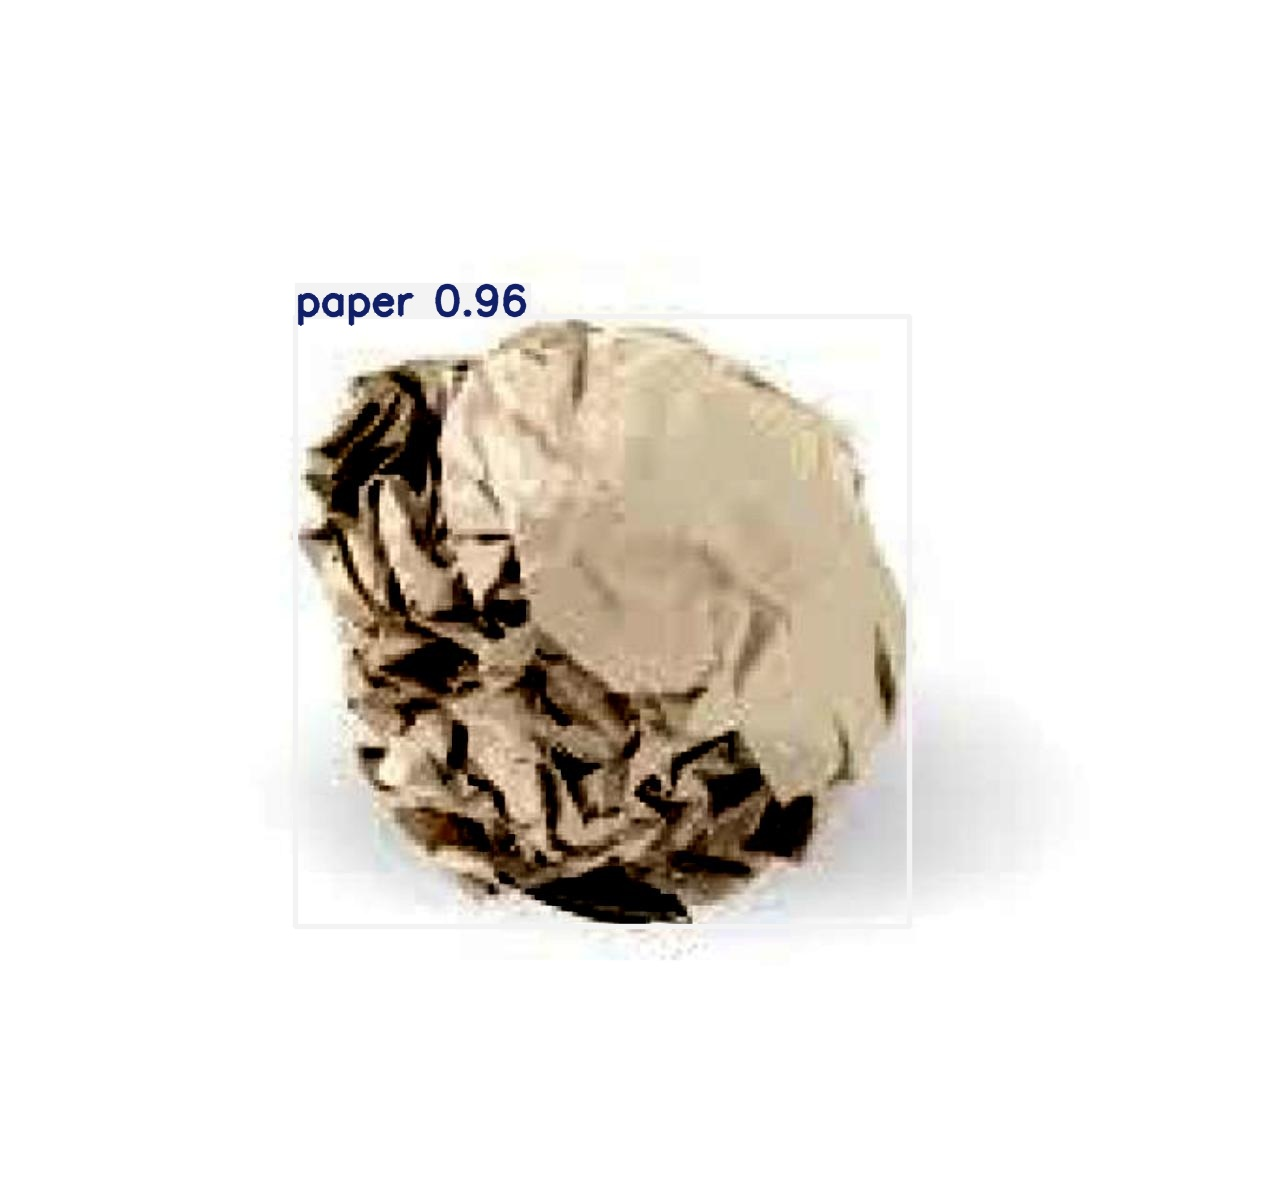

In [8]:
# Baixa o uso.py do repositório e coloca o modelo treinado na mesma pasta
!wget -q -O uso.py https://raw.githubusercontent.com/data-science-unicamp/aplicacoes-data-science/main/atividade3/uso.py
!cp /content/runs/thesis/weights/best.pt .

# Sorteia 3 imagens de teste; para cada uma, roda o uso.py e mostra a imagem com as detecções
for p in random.sample(glob.glob(f"{root}/test/images/*"), 3):
    !python uso.py "{p}"
    display(Image(f"/content/runs/detect/predict/{os.path.basename(p)}", width=400))

In [9]:
# Baixa o best.pt, os gráficos e as imagens de teste num zip
from google.colab import files

!cd /content && zip -qr runs.zip runs
files.download("/content/runs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>